# 1. Compreensão do Problema

- Interpretar o contexto do problema.
- Definir claramente a variável alvo.
- Realizar a transformação da variável de qualidade em classificação binária.

## Objetivo

Desenvolver um modelo de classificação capaz de prever a qualidade de um vinho com base em suas características físico-químicas.
Para simplificar o problema, a variável de qualidade deverá ser transformada em uma classificação binária, por exemplo:
- Vinho de Alta Qualidade: nota >= 7
- Vinho de Baixa/Média Qualidade: nota < 7

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.metrics import classification_report, make_scorer, f1_score
from sklearn.utils import resample

from src.pipelines import (pipeline_logistic_regression, pipeline_svc, pipeline_random_forest, pipeline_knn)

SEMENTE = 42

In [3]:
df_wine = pd.read_csv('../data/WineQT.csv')

In [4]:
df_wine.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


## Variável Alvo

Deverá ser medida a variável 'quality'.

A mesma foi transformada em uma categoria binária ('quality_classification'), onde:
- 0 = vinho de baixa/média qualidade com nota < 7
- 1 = vinho de alta qualidade com nota >= 7

In [5]:
df_wine['quality_classification'] = np.select(
    [
        df_wine['quality'] < 7,
        df_wine['quality'] >= 7
    ],
    [
        0,
        1
    ]
)

df_wine.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id,quality_classification
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4,0


# 2. Análise Exploratória de Dados (EDA)

- Investigar a distribuição das variáveis.
- Identificar correlações entre as variáveis e justificar cada uma delas.
- Detectar possíveis outliers ou valores inconsistentes.
- Analisar o balanceamento das classes

## Análise Inicial

In [6]:
df_wine.shape

(1143, 14)

In [7]:
df_wine.info()

<class 'pandas.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   fixed acidity           1143 non-null   float64
 1   volatile acidity        1143 non-null   float64
 2   citric acid             1143 non-null   float64
 3   residual sugar          1143 non-null   float64
 4   chlorides               1143 non-null   float64
 5   free sulfur dioxide     1143 non-null   float64
 6   total sulfur dioxide    1143 non-null   float64
 7   density                 1143 non-null   float64
 8   pH                      1143 non-null   float64
 9   sulphates               1143 non-null   float64
 10  alcohol                 1143 non-null   float64
 11  quality                 1143 non-null   int64  
 12  Id                      1143 non-null   int64  
 13  quality_classification  1143 non-null   int64  
dtypes: float64(11), int64(3)
memory usage: 125.1 KB


In [8]:
# Verificando o dataset

print("Linhas duplicadas:", df_wine.duplicated().sum())
print()

print("Valores ausentes por coluna:")
print(df_wine.isnull().sum())
print()

print("Valores unicos por coluna:")
print(df_wine.nunique())

Linhas duplicadas: 0

Valores ausentes por coluna:
fixed acidity             0
volatile acidity          0
citric acid               0
residual sugar            0
chlorides                 0
free sulfur dioxide       0
total sulfur dioxide      0
density                   0
pH                        0
sulphates                 0
alcohol                   0
quality                   0
Id                        0
quality_classification    0
dtype: int64

Valores unicos por coluna:
fixed acidity               91
volatile acidity           135
citric acid                 77
residual sugar              80
chlorides                  131
free sulfur dioxide         53
total sulfur dioxide       138
density                    388
pH                          87
sulphates                   89
alcohol                     61
quality                      6
Id                        1143
quality_classification       2
dtype: int64


In [9]:
df_wine.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,1143.0,8.311111,1.747595,4.60000,7.10000,7.90000,9.100000,15.90000
volatile acidity,1143.0,0.531339,0.179633,0.12000,0.39250,0.52000,0.640000,1.58000
citric acid,1143.0,0.268364,0.196686,0.00000,0.09000,0.25000,0.420000,1.00000
residual sugar,1143.0,2.532152,1.355917,0.90000,1.90000,2.20000,2.600000,15.50000
chlorides,1143.0,0.086933,0.047267,0.01200,0.07000,0.07900,0.090000,0.61100
free sulfur dioxide,1143.0,15.615486,10.250486,1.00000,7.00000,13.00000,21.000000,68.00000
total sulfur dioxide,1143.0,45.914698,32.782130,6.00000,21.00000,37.00000,61.000000,289.00000
density,1143.0,0.996730,0.001925,0.99007,0.99557,0.99668,0.997845,1.00369
pH,1143.0,3.311015,0.156664,2.74000,3.20500,3.31000,3.400000,4.01000
sulphates,1143.0,0.657708,0.170399,0.33000,0.55000,0.62000,0.730000,2.00000


In [10]:
print("Contagem quality_classification:")
print(df_wine['quality_classification'].value_counts())
print()

print("Percentual quality_classification:")
print(df_wine['quality_classification'].value_counts(normalize=True) * 100)



Contagem quality_classification:
quality_classification
0    984
1    159
Name: count, dtype: int64

Percentual quality_classification:
quality_classification
0    86.089239
1    13.910761
Name: proportion, dtype: float64


Desbalanceamento entre as classes. Há muito mais vinhos de média/baixa qualidade, do que vinhos de alta qualidade.

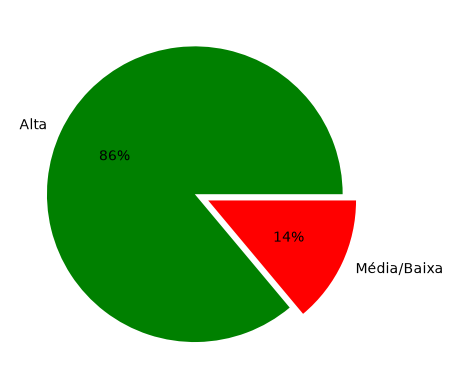

In [11]:
categorias = ['Alta', 'Média/Baixa']
plt.pie(df_wine['quality_classification'].value_counts(), labels=categorias, autopct='%.0f%%', explode=(0, 0.1), colors=('g', 'r'))
plt.show()

## Entendendo como as variáveis estão distribuídas

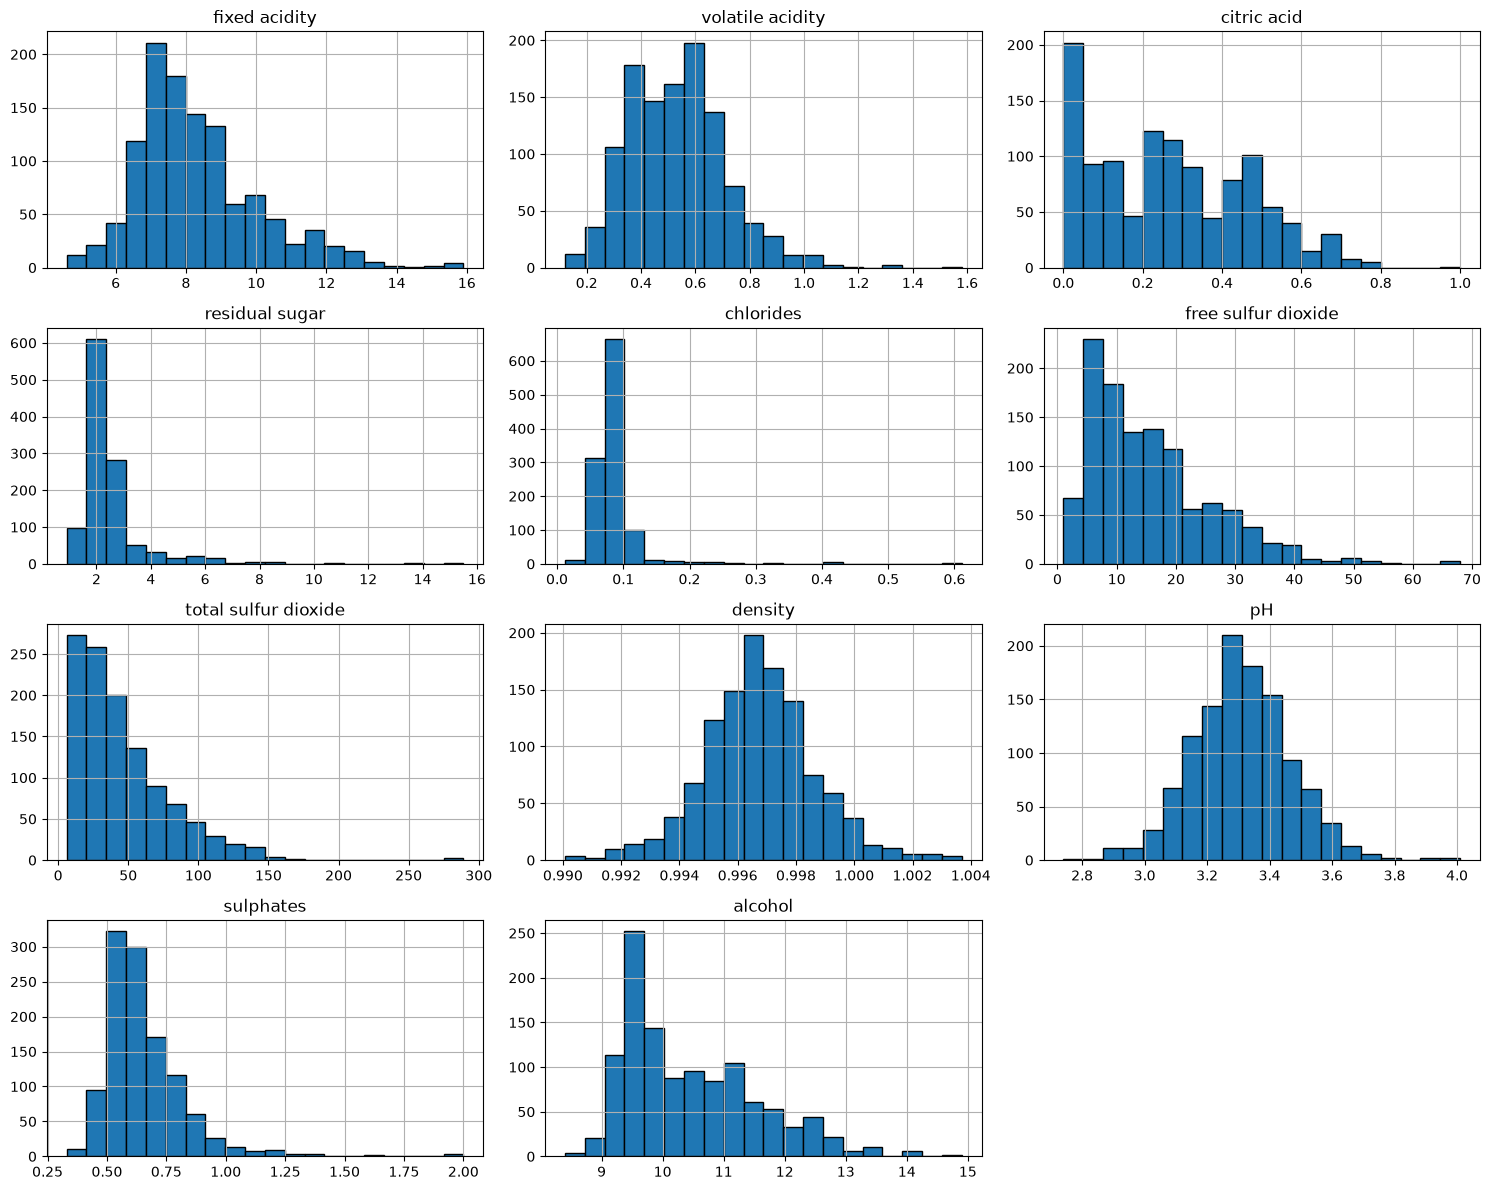

In [12]:
features = df_wine.drop(
    columns=['Id', 'quality', 'quality_classification']
)

features.hist(
    figsize=(15, 12),
    bins=20,
    edgecolor='black'
)

plt.tight_layout()
plt.show()

## Entendendo os outliers

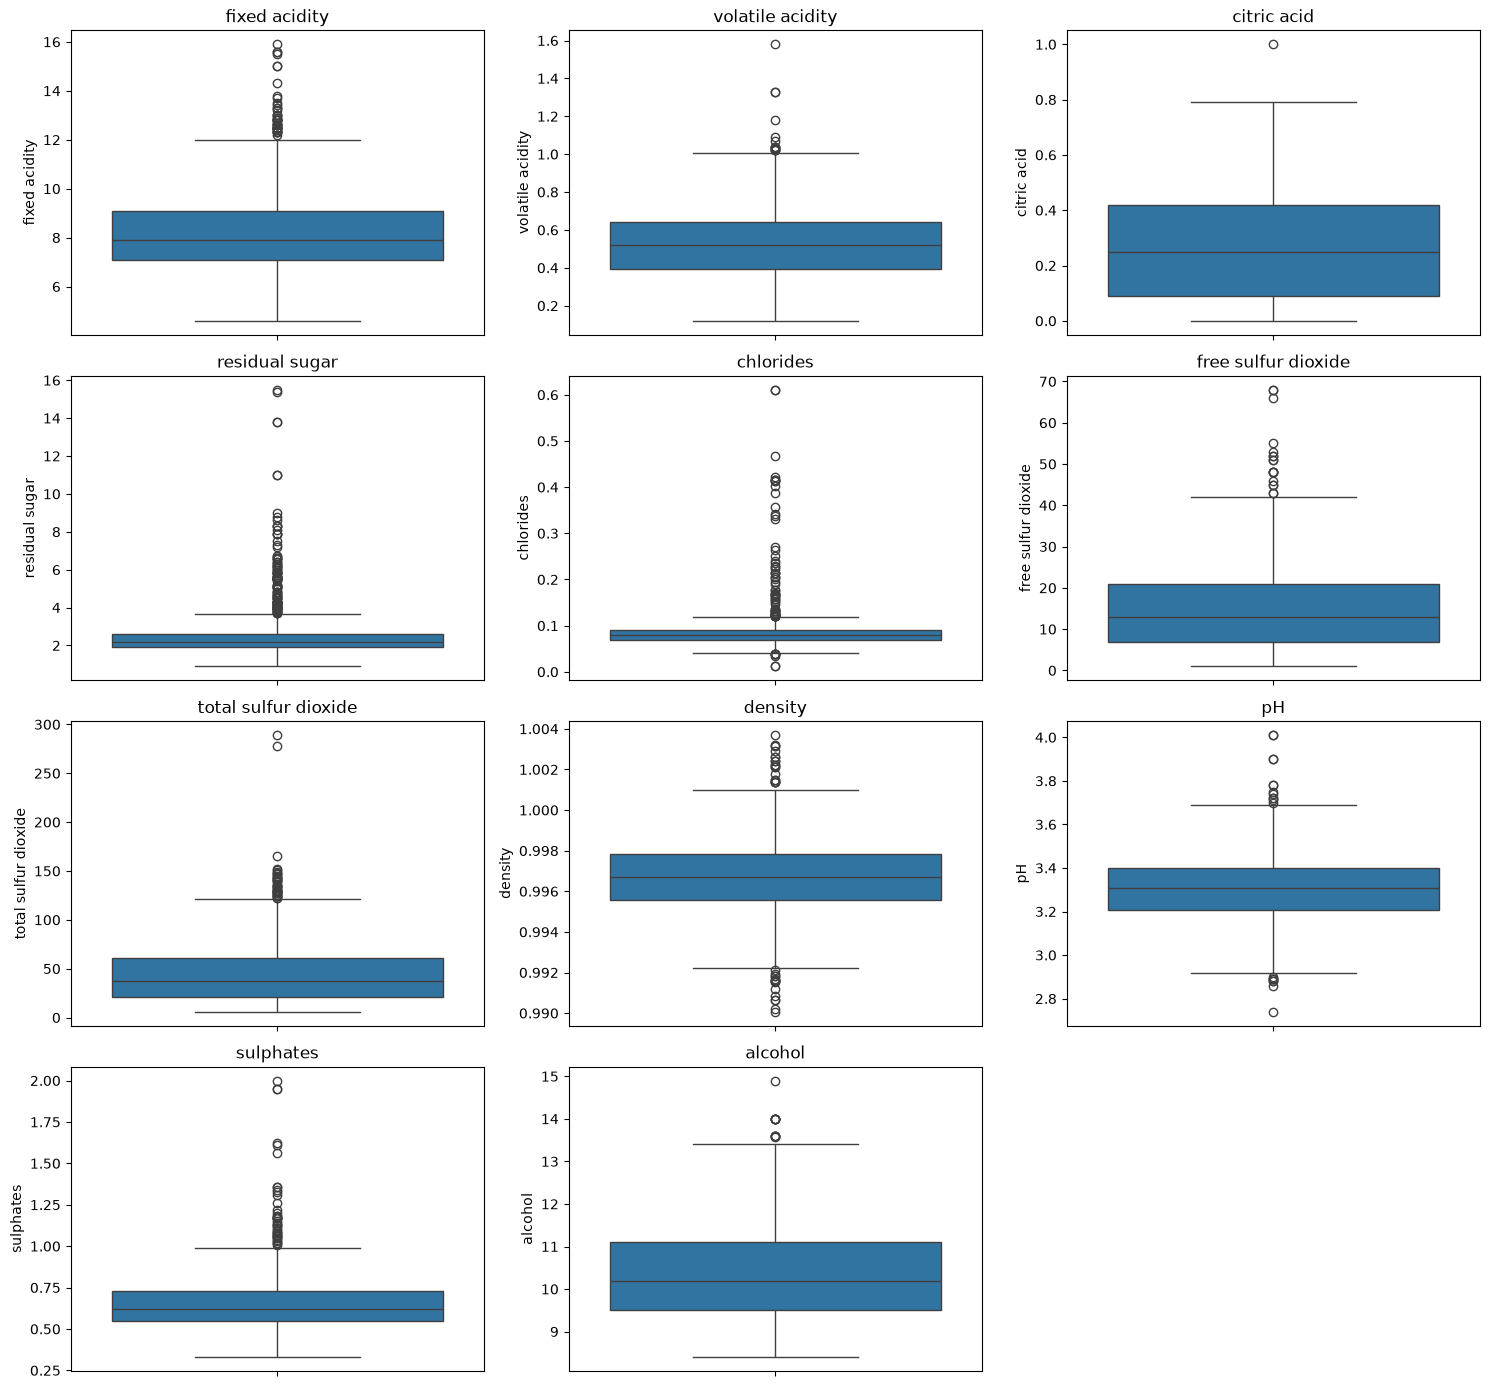

In [13]:
fig, axes = plt.subplots(4, 3, figsize=(15, 14))

for ax, column in zip(axes.flatten(), features.columns):
    sns.boxplot(data=df_wine, y=column, ax=ax)
    ax.set_title(column)

# Remove o último gráfico vazio
axes.flatten()[-1].axis('off')

plt.tight_layout()
plt.show()

Muitos outliers, deverão ser mantidos, e avaliados o comportamento dos modelos posteriormente.

## Entendendo a correlação entre as variáveis

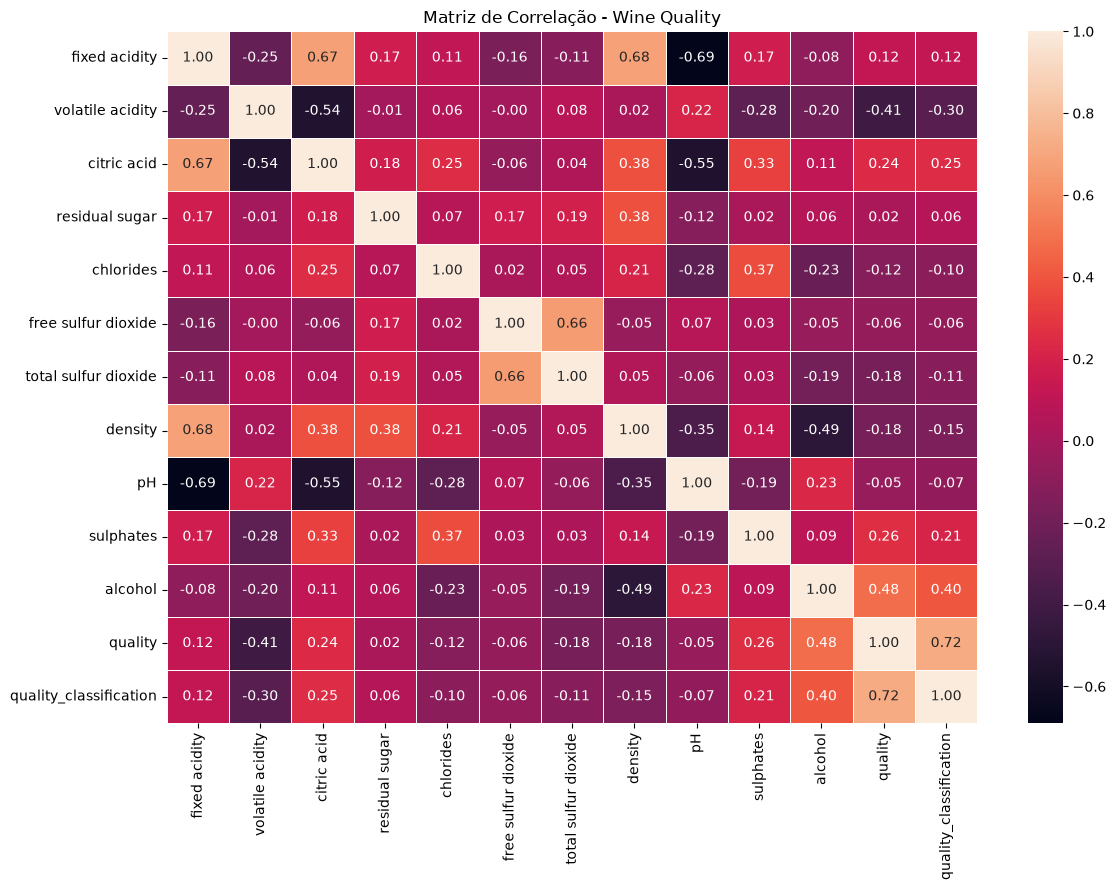

In [14]:
correlation = df_wine.drop(columns=['Id']).corr().round(2) # removendo a coluna ID da análise, porque ela é um valor único

plt.figure(figsize=(12,9))    
sns.heatmap(data=correlation, annot=True, linewidths=0.5, fmt='.2f')

plt.title('Matriz de Correlação - Wine Quality')
plt.tight_layout()
plt.show()

Acidez Volátil (volatile acidity), Acidez Cítrica (citric acid), Sulfatos (sulphates) e Teor Alcoólico (alcohol) parecem influenciar na qualidade do vinho.

# 3. Pré-processamento de Dados

- Tratamento de dados faltantes (se houver).
- Normalização ou padronização de variáveis numéricas.
- Criação de novas features (feature engineering), se considerado relevante.

## Separação da base de treino e teste

In [15]:
# Separação das variáveis preditoras e variável alvo

x = df_wine.drop(columns=['Id', 'quality', 'quality_classification'])
y = df_wine['quality_classification'] # variável alvo (target)

In [16]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, stratify=y, random_state=SEMENTE) #20% para teste e 80% de treino

In [17]:
print(f'Treino: {x_train.shape}')
print(f'Teste: {x_test.shape}')

print('\nDistribuição das classes - Treino:')
print(y_train.value_counts(normalize=True) * 100)

print('\nDistribuição das classes - Teste:')
print(y_test.value_counts(normalize=True) * 100)

Treino: (914, 11)
Teste: (229, 11)

Distribuição das classes - Treino:
quality_classification
0    86.105033
1    13.894967
Name: proportion, dtype: float64

Distribuição das classes - Teste:
quality_classification
0    86.026201
1    13.973799
Name: proportion, dtype: float64


## Balanceamento das classes (Oversampling)

In [18]:
# Preservando o conjunto de teste original, sem balancear

x_train_0 = x_train[y_train == 0]
x_train_1 = x_train[y_train == 1]

y_train_0 = y_train[y_train == 0]
y_train_1 = y_train[y_train == 1]

print('Classe 0:', len(x_train_0))
print('Classe 1:', len(x_train_1))

Classe 0: 787
Classe 1: 127


In [19]:
# Aplicando oversampling
x_train_1_resampled, y_train_1_resampled = resample(x_train_1, y_train_1, replace=True, n_samples=len(x_train_0), random_state=SEMENTE)

In [20]:
# Juntando os dados
x_train_balanced = pd.concat([x_train_0, x_train_1_resampled])
y_train_balanced = pd.concat([y_train_0, y_train_1_resampled])

In [21]:
print(y_train_balanced.value_counts())

quality_classification
0    787
1    787
Name: count, dtype: int64


## Feature Scaling

A padronização da escala dos dados será feita dentro do pipeline (./src/pipelines.py), afim de evitar duplicidade de processamento e vazamento de dados.

# 4. Desenvolvimento e Avaliação dos Modelos

- Treinar pelo menos dois modelos de classificação, e comparar o desempenho entre eles.
- Avaliar os modelos utilizando métricas adequadas. Também deve ser realizada uma comparação entre os modelos testados.

## Treinando os modelos (sem balanceamento)

In [22]:
# Regressão Logística
pipeline_logistic_regression.fit(x_train, y_train)

# SVC
pipeline_svc.fit(x_train, y_train)

# Random Forest
pipeline_random_forest.fit(x_train, y_train)

# KNN
pipeline_knn.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['fixed acidity','volatile acidity','citric acid',...,'pH','sulphates', 'alcohol']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [23]:
y_pred_logistic_regression = pipeline_logistic_regression.predict(x_test)

y_pred_svc = pipeline_svc.predict(x_test)

y_pred_random_forest = pipeline_random_forest.predict(x_test)

y_pred_knn = pipeline_knn.predict(x_test)

In [24]:
# Conferindo se todos os modelos avaliaram a mesma quantidade de registros

print('Regressão Logística:', len(y_pred_logistic_regression))
print('SVC:', len(y_pred_svc))
print('Random Forest:', len(y_pred_random_forest))
print('KNN:', len(y_pred_knn))
print('Valores reais:', len(y_test))

Regressão Logística: 229
SVC: 229
Random Forest: 229
KNN: 229
Valores reais: 229


### Resultados iniciais dos modelos (sem balanceamento)

In [25]:
print('Regressão Logística')
print(classification_report(y_test, y_pred_logistic_regression))

print('SVC')
print(classification_report(y_test, y_pred_svc))

print('Random Forest')
print(classification_report(y_test, y_pred_random_forest))

print('KNN')
print(classification_report(y_test, y_pred_knn))

Regressão Logística
              precision    recall  f1-score   support

           0       0.94      0.82      0.88       197
           1       0.38      0.69      0.49        32

    accuracy                           0.80       229
   macro avg       0.66      0.75      0.68       229
weighted avg       0.86      0.80      0.82       229

SVC
              precision    recall  f1-score   support

           0       0.95      0.83      0.89       197
           1       0.41      0.72      0.52        32

    accuracy                           0.82       229
   macro avg       0.68      0.78      0.70       229
weighted avg       0.87      0.82      0.84       229

Random Forest
              precision    recall  f1-score   support

           0       0.94      0.93      0.94       197
           1       0.60      0.66      0.63        32

    accuracy                           0.89       229
   macro avg       0.77      0.79      0.78       229
weighted avg       0.90      0.89   

Como o Random Forest foi o que trouxe melhor f1-score, então será feita uma busca de melhor parâmetros para este modelo. 

### Validação Cruzada

In [26]:
# Busca de hiperparâmetros que maximizam o f1-score

param_grid = {
    'model__n_estimators': [100, 200, 300],
    'model__max_depth': [None, 5, 10, 15],
    'model__min_samples_split': [2, 5, 10]
}

scorer = make_scorer(f1_score, average='macro')

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)

grid = GridSearchCV(estimator=pipeline_random_forest,
                    param_grid=param_grid,
                    scoring=scorer,
                    cv=cv, n_jobs=-1)

grid.fit(x_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__max_depth': [None, 5, ...], 'model__min_samples_split': [2, 5, ...], 'model__n_estimators': [100, 200, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",make_scorer(f...average=macro)
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:

In [27]:
print('Melhores parâmetros:', grid.best_params_)
print('Melhor Macro F1:', grid.best_score_)

Melhores parâmetros: {'model__max_depth': None, 'model__min_samples_split': 2, 'model__n_estimators': 300}
Melhor Macro F1: 0.7777270322107016


In [28]:
best_model = grid.best_estimator_

y_pred_rf_tuned = best_model.predict(x_test)

print(classification_report(y_test, y_pred_rf_tuned))

              precision    recall  f1-score   support

           0       0.94      0.92      0.93       197
           1       0.57      0.62      0.60        32

    accuracy                           0.88       229
   macro avg       0.75      0.77      0.76       229
weighted avg       0.89      0.88      0.88       229



- O Random Forest original continua sendo a melhor versão entre as duas.
- A busca de hiperparâmetros não trouxe ganho de generalização.

## Treinando os modelos (com balanceamento)

In [29]:
# Regressão Logística
pipeline_logistic_regression.fit(x_train_balanced, y_train_balanced)

# SVC
pipeline_svc.fit(x_train_balanced, y_train_balanced)

# Random Forest
pipeline_random_forest.fit(x_train_balanced, y_train_balanced)

# KNN
pipeline_knn.fit(x_train_balanced, y_train_balanced)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['fixed acidity','volatile acidity','citric acid',...,'pH','sulphates', 'alcohol']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [30]:
y_pred_logistic_regression_balanced = pipeline_logistic_regression.predict(x_test)

y_pred_svc_balanced = pipeline_svc.predict(x_test)

y_pred_random_forest_balanced = pipeline_random_forest.predict(x_test)

y_pred_knn_balanced = pipeline_knn.predict(x_test)

In [31]:
# Conferindo se todos os modelos avaliaram a mesma quantidade de registros

print('Regressão Logística:', len(y_pred_logistic_regression_balanced))
print('SVC:', len(y_pred_svc_balanced))
print('Random Forest:', len(y_pred_random_forest_balanced))
print('KNN:', len(y_pred_knn_balanced))
print('Valores reais:', len(y_test))

Regressão Logística: 229
SVC: 229
Random Forest: 229
KNN: 229
Valores reais: 229


### Resultados iniciais dos modelos (com balanceamento)

In [32]:
print('Regressão Logística')
print(classification_report(y_test, y_pred_logistic_regression_balanced))

print('SVC')
print(classification_report(y_test, y_pred_svc_balanced))

print('Random Forest')
print(classification_report(y_test, y_pred_random_forest_balanced))

print('KNN')
print(classification_report(y_test, y_pred_knn_balanced))

Regressão Logística
              precision    recall  f1-score   support

           0       0.94      0.82      0.88       197
           1       0.39      0.69      0.49        32

    accuracy                           0.80       229
   macro avg       0.66      0.75      0.69       229
weighted avg       0.86      0.80      0.82       229

SVC
              precision    recall  f1-score   support

           0       0.95      0.83      0.89       197
           1       0.41      0.72      0.52        32

    accuracy                           0.82       229
   macro avg       0.68      0.78      0.70       229
weighted avg       0.87      0.82      0.84       229

Random Forest
              precision    recall  f1-score   support

           0       0.94      0.96      0.95       197
           1       0.70      0.59      0.64        32

    accuracy                           0.91       229
   macro avg       0.82      0.78      0.80       229
weighted avg       0.90      0.91   

Mesmo aplicando balanceamento nos dados, o modelo que melhor performou ainda foi o Random Forest.

Embora não tenha melhorado tanto no f1 (aumentando 0.01), a acurácia subiu de 0.86 para 0.91 e macro avg de 0.70 para 0.80.

# 5. Interpretação dos Resultados

- Identificar quais variáveis parecem ter maior influência na qualidade do vinho.
- Discutir possíveis implicações para o processo de produção.

Como o Random Forest foi o modelo que melhor performou, é possível utilizar o atributo feature_importances_ para avaliar o peso de cada variável nas decisões das árvores.

https://scikit-learn.org/stable/auto_examples/ensemble/plot_forest_importances.html

In [34]:
feature_importance = pd.DataFrame({
    'feature': x_train.columns,
    'importance': pipeline_random_forest.named_steps['model'].feature_importances_
})

feature_importance = feature_importance.sort_values(by='importance', ascending=False)

feature_importance

,feature,importance
10,alcohol,0.215842
9,sulphates,0.157088
2,citric acid,0.114697
1,volatile acidity,0.107358
7,density,0.079290
0,fixed acidity,0.068064
6,total sulfur dioxide,0.065451
8,pH,0.053004
4,chlorides,0.051323
3,residual sugar,0.045415


In [35]:
selected_features = [
    'alcohol',
    'sulphates',
    'citric acid',
    'volatile acidity'
]

In [36]:
x_train_selected = x_train[selected_features]
x_test_selected = x_test[selected_features]

In [37]:
from sklearn.base import clone

pipeline_rf_selected = clone(pipeline_random_forest)

In [38]:
pipeline_rf_selected.fit(x_train_selected, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['alcohol','sulphates','citric acid','volatile acidity']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight i

In [39]:
y_pred_rf_selected = pipeline_rf_selected.predict(x_test_selected)

In [40]:
print(classification_report(y_test, y_pred_rf_selected))

              precision    recall  f1-score   support

           0       0.94      0.92      0.93       197
           1       0.57      0.66      0.61        32

    accuracy                           0.88       229
   macro avg       0.76      0.79      0.77       229
weighted avg       0.89      0.88      0.89       229



In [41]:
f1_score(
    y_test,
    y_pred_rf_selected,
    average='macro'
)

0.769643455907008

Embora quatro variáveis tenham concentrado aproximadamente 58,5% da importância total no Random Forest, a utilização de todas as 11 variáveis preditoras apresentou melhor desempenho. Isso sugere que características de menor importância individual também podem contribuir para a capacidade de classificação quando consideradas em conjunto.